# Survival Analysis — Kaplan-Meier Retention Curves

**Objective.** Estimate the customer retention (survival) curve using all observed history, quantify its uncertainty, test whether
segments differ significantly, and translate the result into 24-month margin per customer.

**Why this follows the cohort analysis.** The cohort-average method (notebook 02) only uses customers who have reached a given tenure.
A customer who signed up 10 months ago contributes nothing at month 12, even though their survival through month 10 is informative.
That made long-tenure estimates noisy (±5 pts at month 24). **Kaplan-Meier (KM)** uses every customer for every month they were observed.

**Scope.** Non-parametric (KM makes no assumption about the curve's shape), within observed tenure (≤ 24 months), one segment variable at a time.

---

### Summary of findings

1. **KM confirms the cohort-average curve with more precision.** Retention is 76% / 55% / 41% / 25% / 11.5% at months 1 / 3 / 6 / 12 / 24.
   The 95% CI at month 24 is 2.5× narrower (±2 pts vs. ±5 pts). Median customer lifetime is **4 months**.
2. **24-month margin per customer: $97.8 (bootstrap 95% CI: $95–$101).** A customer is active for an average of 7.9 of their first 24 months.
3. **Common shortcuts cause large errors.** Treating active customers as churned understates value by 30%. Analyzing only churned
   customers ("average lifetime of churners = 4.1 months") understates it by 46%.
4. **Churn risk falls sharply, then levels off.** Monthly churn drops from 24% in month 1 to about 7% by month 6, then stays roughly flat at 7–9%.
5. **All three segment variables differ significantly (log-rank p < 0.001).** Referral customers are worth $125 vs. $85 for paid social.
   Discounted signups are worth $80 vs. $105 without a discount. Annual and monthly plans are close in value ($102 vs. $95) because better retention offsets the lower margin.
6. **Open question for modeling:** segment gaps are roughly, but not perfectly, constant across tenure. Whether a proportional-hazards model
   (Cox) fits is tested in the next analysis.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import restricted_mean_survival_time

from retention import retention_curve
from ltv import ltv

HORIZON = 24
TENURES = range(HORIZON + 1)

customers = pd.read_csv("../data/customers.csv")
customers[["months_observed", "churned"]].describe().T

,count,mean,std,min,25%,50%,75%,max
months_observed,4000.0,5.44050,5.310039,1.0,1.0,3.0,8.0,24.0
churned,4000.0,0.70225,0.457326,0.0,0.0,1.0,1.0,1.0


## 1. Survival data setup

Each customer contributes a **duration** and an **event flag**:

| Column | Role | Meaning |
|---|---|---|
| `months_observed` | duration *T* | months paid (if churned) or months observed so far (if active) |
| `churned` | event | 1 = churn observed, 0 = **censored** (still active, so true lifetime ≥ T) |

**How KM works:** at each month, among customers **still at risk** (active and still observed), compute the share who survive that
month. Then multiply those monthly survival rates together:

$$S(k) = \prod_{j \le k} \left(1 - \frac{\text{churned in month } j}{\text{at risk at start of month } j}\right)$$

A censored customer counts in the "at risk" group for every month they were observed, then leaves the risk set without being counted as churned.

**Key assumption, non-informative censoring:** customers who are censored (recent signups) must have the same churn outlook as those
who remain observed. Here censoring is driven by signup date, and notebook 02 showed retention and mix are stable across cohorts, so the assumption is reasonable.
It would fail if, say, recent signups came from a new low-quality channel.

## 2. Overall retention curve

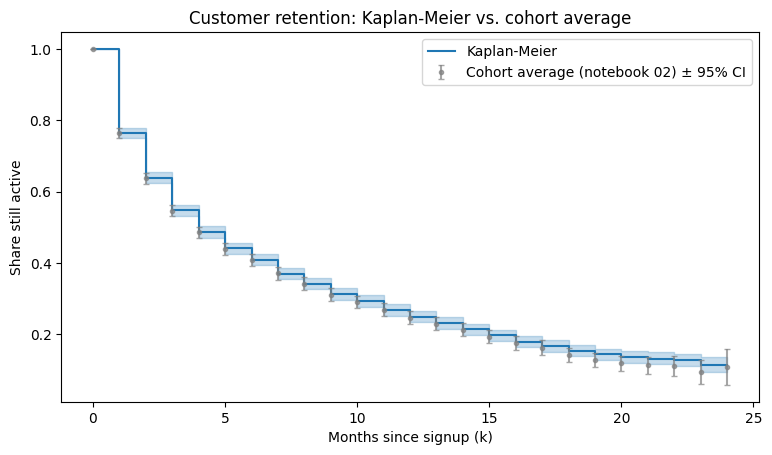

Median lifetime: 4 months


,KM,KM 95% CI width,cohort avg,cohort avg CI width
1,0.764,0.026,0.764,0.026
3,0.548,0.032,0.547,0.032
6,0.409,0.032,0.408,0.034
12,0.249,0.031,0.247,0.036
18,0.155,0.032,0.142,0.040
24,0.115,0.041,0.109,0.101


In [2]:
km = KaplanMeierFitter(label="Kaplan-Meier").fit(customers.months_observed, customers.churned)
pooled = retention_curve(customers, horizon=HORIZON)

fig, ax = plt.subplots(figsize=(9, 4.8))
km.plot_survival_function(ax=ax, ci_show=True)
ax.errorbar(pooled.index, pooled.retention,
            yerr=[pooled.retention - pooled.ci_low, pooled.ci_high - pooled.retention],
            fmt="o", ms=3, color="grey", alpha=0.7, capsize=2, label="Cohort average (notebook 02) ± 95% CI")
ax.set_title("Customer retention: Kaplan-Meier vs. cohort average")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Share still active")
ax.legend()
plt.show()

S_km = km.survival_function_at_times(TENURES)
ci = km.confidence_interval_survival_function_.reindex(TENURES, method="ffill")
compare = pd.DataFrame({
    "KM": S_km.values,
    "KM 95% CI width": (ci.iloc[:, 1] - ci.iloc[:, 0]).values,
    "cohort avg": pooled.retention.values,
    "cohort avg CI width": (pooled.ci_high - pooled.ci_low).values,
}, index=TENURES)
print(f"Median lifetime: {km.median_survival_time_:.0f} months")
compare.loc[[1, 3, 6, 12, 18, 24]].round(3)

**Takeaway:** the two methods agree at every tenure, which confirms the cohort-average curve from notebook 02. KM is much more precise at long
tenures: the CI at month 24 is ±2 pts vs. ±5 pts, because KM uses partial histories that the cohort average discards. Half of customers churn within 4 months.

## 3. What does this mean in dollars?

Two related numbers:
- **Expected active months in the first 24** (restricted mean survival time, RMST) = area under the KM curve up to month 24.
- **24-month margin per customer** = Σ S(k) × monthly margin ÷ 1.01^k. We use a bootstrap for its CI: resample customers, refit KM and recompute 1,000 times.

In [3]:
margin = customers.monthly_margin.mean()
rmst = restricted_mean_survival_time(km, t=HORIZON)
value = ltv(S_km.values, margin)

rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    sample = customers.sample(len(customers), replace=True, random_state=rng.integers(1e9))
    k = KaplanMeierFitter().fit(sample.months_observed, sample.churned)
    boot.append(ltv(k.survival_function_at_times(TENURES).values, sample.monthly_margin.mean()))
lo, hi = np.percentile(boot, [2.5, 97.5])

print(f"Expected active months (first 24): {rmst:.1f}")
print(f"24-month margin per customer:       ${value:.1f}  (95% CI ${lo:.1f}–${hi:.1f})")

Expected active months (first 24): 7.9
24-month margin per customer:       $97.8  (95% CI $94.7–$101.0)


**Takeaway:** a new customer is worth about **$98** in margin over 24 months, with a tight interval (±$3). As a rough acquisition guideline, CAC above about $95
would be unprofitable within two years for the average customer. Segment-level caps (section 6) are more useful than one blended cap.

## 4. How much do common shortcuts cost?

Two mistakes often seen in practice:
- **Censored counted as churned:** treat every customer's last observed month as a churn date.
- **Churned customers only:** drop active customers and compute lifetime from churners. This is the "average lifetime of customers who left" metric.

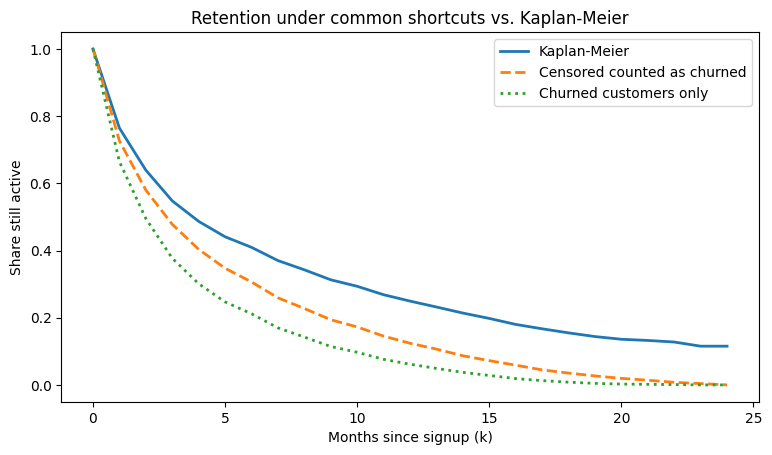

,M12 retention,24m margin per customer,value error
Kaplan-Meier,0.249,97.811,0.000
Censored counted as churned,0.124,68.808,-0.297
Churned customers only,0.062,52.755,-0.461


In [4]:
all_churned = KaplanMeierFitter(label="Censored counted as churned").fit(customers.months_observed, np.ones(len(customers)))
churners = customers[customers.churned == 1]
churners_only = KaplanMeierFitter(label="Churned customers only").fit(churners.months_observed, churners.churned)

fig, ax = plt.subplots(figsize=(9, 4.8))
for model, style in [(km, "-"), (all_churned, "--"), (churners_only, ":")]:
    s = model.survival_function_at_times(TENURES)
    ax.plot(s.index, s.values, ls=style, lw=2, label=model._label)
ax.set_title("Retention under common shortcuts vs. Kaplan-Meier")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Share still active")
ax.legend()
plt.show()

shortcut = pd.DataFrame({
    m._label: {
        "M12 retention": m.survival_function_at_times(12).iloc[0],
        "24m margin per customer": ltv(m.survival_function_at_times(TENURES).values, margin),
    } for m in [km, all_churned, churners_only]
}).T
shortcut["value error"] = shortcut["24m margin per customer"] / value - 1
shortcut.round(3)

**Takeaway:** both shortcuts badly understate customer value: by 30% when censored customers are counted as churned, and by 46% when only churned
customers are used. The "churners only" view is especially misleading because it leaves out exactly the long-lived customers who create most of the value.
**Any lifetime or LTV figure that doesn't state how active customers were handled should be treated with suspicion.**

## 5. When do customers churn? Monthly churn risk (hazard)

Hazard at month k = churned in month k ÷ at risk at the start of month k. This is the correct version of the month-over-month view in
notebook 02, because it always uses the same risk set and so can't go above 100%.

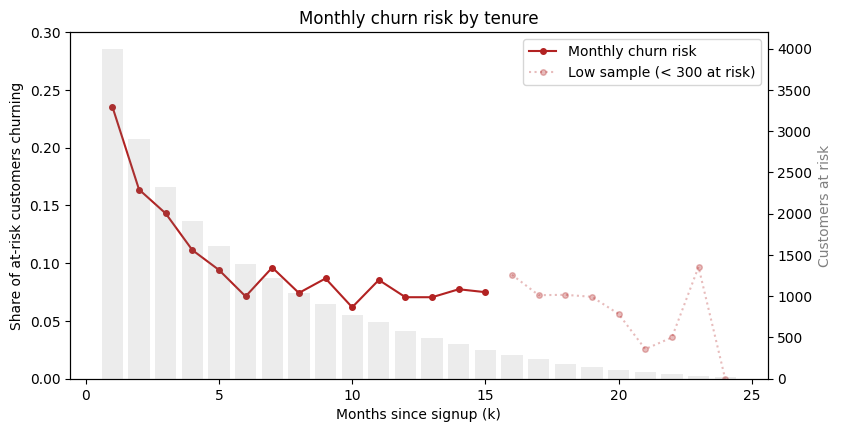

event_at,1.0,2.0,3.0,4.0,6.0,9.0,12.0,18.0
hazard,0.236,0.164,0.143,0.111,0.071,0.087,0.071,0.073


In [5]:
events = km.event_table.loc[1:HORIZON]
hazard = events.observed / events.at_risk
reliable = events.at_risk >= 300

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(hazard.index[reliable], hazard[reliable], marker="o", ms=4, color="firebrick", label="Monthly churn risk")
ax1.plot(hazard.index[~reliable], hazard[~reliable], marker="o", ms=4, color="firebrick", alpha=0.3,
         ls=":", label="Low sample (< 300 at risk)")
ax1.set_xlabel("Months since signup (k)")
ax1.set_ylabel("Share of at-risk customers churning")
ax1.set_ylim(0, 0.3)
ax2 = ax1.twinx()
ax2.bar(events.index, events.at_risk, color="grey", alpha=0.15)
ax2.set_ylabel("Customers at risk", color="grey")
ax1.set_title("Monthly churn risk by tenure")
ax1.legend(loc="upper right")
plt.show()

hazard.loc[[1, 2, 3, 4, 6, 9, 12, 18]].round(3).to_frame("hazard").T

**Takeaway:** churn risk is highest in month 1 (24%), falls quickly through month 6, then levels off at about 7–9% per month. Two implications:
- **Retention efforts pay off most in the first 3 months.** That's where most of the churn happens.
- **Forecasting:** assuming constant churn based on early months would badly understate long-run retention. A model that projects
  beyond the observed data needs to capture this declining-then-flat shape (Weibull with a decreasing hazard, or sBG).

## 6. Retention by segment, with significance tests

The **log-rank test** asks: *if all groups truly had the same survival curve, how likely would differences this large be by chance?*
It compares the churn observed in each group with the churn expected under "no difference", month by month, using the full censored data.

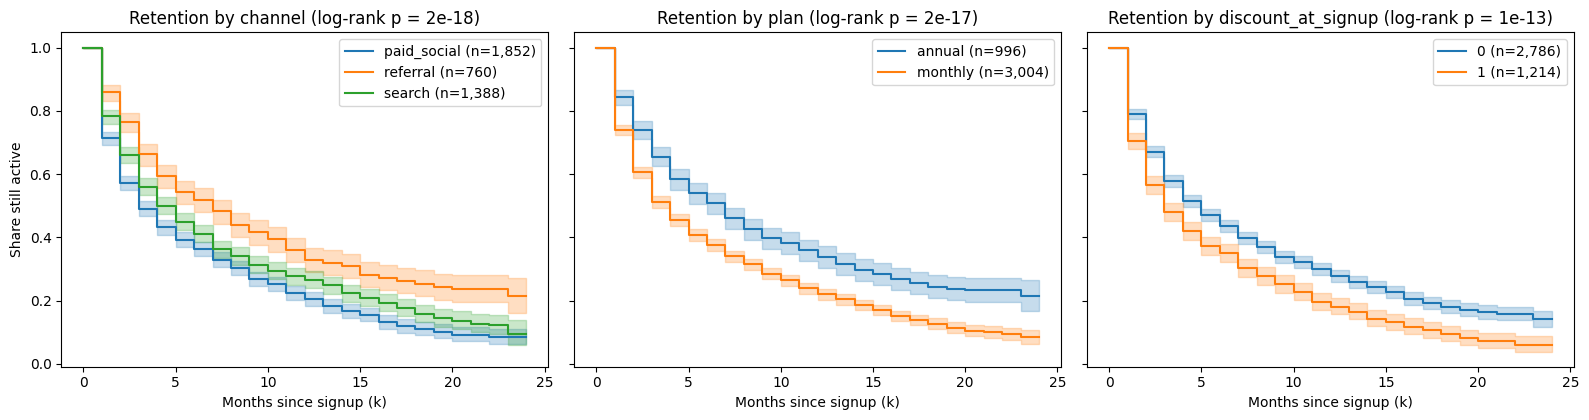

,chi-square,p-value
channel,81.415036,2.093869e-18
plan,72.251973,1.894012e-17
discount_at_signup,55.045910,1.177471e-13


customers     M3     M6    M12  \
segment            value                                         
channel            paid_social       1852  0.491  0.363  0.204   
                   referral           760  0.663  0.518  0.328   
                   search            1388  0.561  0.412  0.267   
plan               annual             996  0.655  0.509  0.338   
                   monthly           3004  0.512  0.377  0.220   
discount_at_signup 0                 2786  0.577  0.435  0.278   
                   1                 1214  0.480  0.350  0.181   

                                median lifetime  24m margin per customer  
segment            value                                                  
channel            paid_social              3.0                   85.269  
                   referral                 7.0                  125.037  
                   search                   5.0                   99.310  
plan               annual                   7.0                  101.935  
                   monthly                  4.0                   94.651  
discount_at_signup 0                        5.0                  105.335  
                   1                        3.0                   80.328

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
rows, tests = [], {}
for ax, col in zip(axes, ["channel", "plan", "discount_at_signup"]):
    for value_, grp in customers.groupby(col):
        k = KaplanMeierFitter(label=f"{value_} (n={len(grp):,})").fit(grp.months_observed, grp.churned)
        k.plot_survival_function(ax=ax, ci_show=True)
        s = k.survival_function_at_times(TENURES)
        rows.append({"segment": col, "value": value_, "customers": len(grp),
                     "M3": s[3], "M6": s[6], "M12": s[12], "median lifetime": k.median_survival_time_,
                     "24m margin per customer": ltv(s.values, grp.monthly_margin.mean())})
    test = multivariate_logrank_test(customers.months_observed, customers[col], customers.churned)
    tests[col] = {"chi-square": test.test_statistic, "p-value": test.p_value}
    ax.set_title(f"Retention by {col} (log-rank p = {test.p_value:.0e})")
    ax.set_xlabel("Months since signup (k)")
axes[0].set_ylabel("Share still active")
plt.tight_layout()
plt.show()

display(pd.DataFrame(tests).T)
pd.DataFrame(rows).set_index(["segment", "value"]).round(3)

**Takeaway:** every segment variable separates the curves, and none of the differences are plausibly due to chance (all p < 0.001).
- **Channel:** referral customers are worth about $125 over 24 months, search about $99 and paid social about $85. Paid social is the largest channel, so a CAC cap set
  using the blended $98 would **overpay** for paid social customers and **underpay** for referral customers.
- **Discount:** discounted customers are worth about $80 vs. $105 for non-discounted. The discount must lift conversion enough to make up for that gap.
- **Plan:** annual customers are much stickier (median lifetime 7 vs. 4 months), but their lower margin brings their 24-month value close to monthly customers ($102 vs. $95).

Caveat: each comparison is **one variable at a time**. If segments overlapped (for example if most discounts went to paid social), the
effects would be mixed together. Notebook 02 showed overlap is low, and a multivariable model will separate them properly.

## 7. Do segment differences hold steady across tenure?

This decides which model comes next. A proportional-hazards model (Cox) assumes each segment's churn risk is a **constant multiple** of the
baseline's at every tenure. We compare the ratio of churn rates (segment vs. reference) across three tenure windows.

In [7]:
def window_hazard(d, lo, hi):
    """Churn events / customer-months at risk over tenure months lo..hi."""
    events_ = ((d.churned == 1) & d.months_observed.between(lo, hi)).sum()
    exposure = sum((d.months_observed >= k).sum() for k in range(lo, hi + 1))
    return events_ / exposure

windows = {"months 1-3": (1, 3), "months 4-12": (4, 12), "months 13-24": (13, 24)}
ratios = {}
for col, ref in [("channel", "search"), ("plan", "monthly"), ("discount_at_signup", 0)]:
    base = customers[customers[col] == ref]
    for value_, grp in customers.groupby(col):
        if value_ == ref:
            continue
        ratios[f"{col} = {value_} vs {ref}"] = {
            w: window_hazard(grp, *rng_) / window_hazard(base, *rng_) for w, rng_ in windows.items()}
pd.DataFrame(ratios).T.round(2)

,months 1-3,months 4-12,months 13-24
channel = paid_social vs search,1.24,1.09,1.15
channel = referral vs search,0.71,0.88,0.48
plan = annual vs monthly,0.64,0.82,0.57
discount_at_signup = 1 vs 0,1.34,1.28,1.60


**Takeaway:** the direction of every effect is consistent across tenure (paid social and discount always higher risk; referral and annual
always lower), but the size varies. For example, referral's advantage is weaker in months 4–12 than early or late. The late window
is based on few customers, so some of this is noise. Whether the variation is real enough to violate the proportional-hazards assumption is tested
formally in the next analysis.

## 8. Limitations

- **One variable at a time.** KM curves and log-rank tests don't adjust for other segments. A multivariable model is needed to isolate each effect.
- **No extrapolation.** KM stops at the longest observed tenure (24 months) and says nothing beyond it.
- **Needs long history.** These estimates use two years of data. For a new channel or product with only a few months of data, KM
  can only describe those first few months, so it can't answer "what will this customer be worth?"
- **Non-informative censoring is assumed.** It's supported by stable cohorts (notebook 02), but would need re-checking if the acquisition mix shifts.

## 9. Next steps

1. **Cox proportional-hazards model:** estimate each segment's effect while holding the others constant, and formally test the proportional-hazards assumption (section 7).
2. **Parametric models (Weibull, sBG):** fit the curve's *shape* so retention can be projected beyond observed tenure, and backtest
   whether a model fitted on only the first ~6 months recovers the 12–24 month retention observed here.
